# Taller: Reducción de Dimensiones + Clustering (PCA + K-Means)


### Aprendizaje No Supervisado — Perfiles de estudiantes y segmentación de tiendas con `StandardScaler`, `PCA` y `KMeans`


**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 23-10-2026

> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller


Al finalizar este taller el estudiante será capaz de:

1. Encadenar `StandardScaler` → `PCA` → `KMeans` en un solo `Pipeline` y explicar el papel de cada paso.
2. Decidir cuántas componentes conservar con la **varianza explicada** e interpretar qué significa cada componente con sus **loadings**.
3. Elegir el número de clusters **K** con el **método del codo** y el **coeficiente de Silhouette**, y nombrar cada perfil a partir de sus **centroides en escala original**.
4. Leer un **biplot** con clusters para explicar qué variables separan a los grupos.
5. Comprobar con datos si aplicar PCA **cambia** los clusters o solo ayuda a **visualizarlos**.
6. Entrenar el modelo final con el 100% de los datos, **exportarlo con `joblib`** y asignar perfiles a casos nuevos.


## Flujo de trabajo


```
Datos originales → StandardScaler → PCA (2 componentes) → KMeans → Interpretación en escala original
```

* **PCA** resume variables correlacionadas en pocas componentes nuevas y nos permite **dibujar** los datos en 2D.
* **K-Means** agrupa los puntos en ese espacio reducido.
* La **interpretación** siempre se hace volviendo a las variables originales (horas, notas, dólares…), no a PC1 y PC2.


## Datasets (sintéticos, sin valores nulos, sin columna de etiqueta)


| Parte | Archivo | Filas | Variables (las 6 entran en el modelo) |
| --- | --- | --- | --- |
| A y C | `estudiantes_universidad_ecuador.csv` | 5 000 estudiantes | `horas_estudio_semana`, `nota_promedio`, `porcentaje_asistencia`, `horas_pantalla_dia`, `participacion_clase`, `tareas_entregadas_pct` |
| B | `tiendas_quito.csv` | 5 000 tiendas | `ventas_promedio_semanal`, `num_productos_distintos`, `ticket_promedio`, `rotacion_inventario`, `hora_pico_trafico`, `porcentaje_clientes_frecuentes` |

Ningún archivo tiene una columna que diga a qué grupo pertenece cada fila: **eso es lo que el modelo debe descubrir**.


## Estructura del taller


| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga, exploración y correlaciones (estudiantes) |
| A2 | Guiado | `Pipeline` escalar + PCA y varianza explicada |
| A3 | Guiado | Loadings: qué significa PC1 y PC2 |
| A4 | Guiado | Mapa PCA de los estudiantes (sin clusters) |
| A5 | Guiado | Elegir K: codo + Silhouette sobre las 2 componentes |
| A6 | Guiado | `Pipeline` completo: escalar + PCA + K-Means |
| A7 | Guiado | Mapa de clusters y centroides |
| A8 | Guiado | Perfiles en escala original |
| A9 | Guiado | Biplot: clusters + flechas de las variables |
| A10 | Guiado | ¿PCA cambia los clusters? K-Means con vs. sin PCA |
| B1–B5 | Autónomo | Segmentación de tiendas de conveniencia en Quito |
| C1–C3 | Guiado | Modelo final (100%), exportación con `joblib` y uso con estudiantes nuevos |


## Rúbrica de evaluación (10 puntos)


| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A10 y C1–C3 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las 3 preguntas de la Parte A | 1.5 |
| B1 · Carga, exploración y correlaciones | Código correcto + respuesta | 1.0 |
| B2 · PCA, varianza explicada y loadings | Código correcto + interpretación de PC1 y PC2 | 1.5 |
| B3 · Elección de K | Código correcto (tabla y 2 gráficos) + K justificado con ambas métricas | 1.5 |
| B4 · Modelo, mapa y perfiles | Código correcto + tabla de perfiles con nombres + una recomendación por segmento | 2.5 |
| B5 · Biplot y comparación con vs. sin PCA | Código correcto + respuestas a las preguntas de reflexión | 2.0 |
| **Total** |  | **10** |


# Parte A — Laboratorio Guiado: Perfiles de Estudiantes Universitarios Ecuatorianos


**Contexto:** una universidad ecuatoriana quiere identificar **perfiles de rendimiento académico** para diseñar
estrategias de apoyo diferenciadas: tutorías, alertas tempranas y programas de reconocimiento.

| Variable | Qué mide | Rango |
| --- | --- | --- |
| `horas_estudio_semana` | Horas semanales dedicadas a estudiar | 0 – 30.4 |
| `nota_promedio` | Promedio de notas | 2.1 – 10 |
| `porcentaje_asistencia` | % de clases a las que asistió | 25.5 – 100 |
| `horas_pantalla_dia` | Horas diarias frente a pantallas de entretenimiento | 0 – 14.4 |
| `participacion_clase` | Nivel de participación en clase | 0 – 10 |
| `tareas_entregadas_pct` | % de tareas entregadas a tiempo | 13.1 – 100 |

**Pregunta de negocio:** ¿existen grupos naturales de estudiantes según sus hábitos y rendimiento? ¿Cuántos perfiles se pueden identificar?


## Bloque A1 · Carga, exploración y correlaciones


In [28]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versión de scikit-learn:", sklearn.__version__)

df = pd.read_csv("estudiantes_universidad_ecuador.csv")
print("Dimensiones:", df.shape)
print("Valores nulos:", df.isnull().sum().sum())
df.head()


Versión de scikit-learn: 1.6.1
Dimensiones: (5000, 6)
Valores nulos: 0


,horas_estudio_semana,nota_promedio,porcentaje_asistencia,horas_pantalla_dia,participacion_clase,tareas_entregadas_pct
0,16.51,7.99,93.60,4.65,8.17,98.98
1,13.42,7.03,82.68,2.49,6.06,67.65
2,8.56,4.57,77.81,3.89,8.03,69.15
3,28.29,6.93,95.04,2.44,7.30,92.52
4,21.74,8.76,86.41,2.96,9.16,89.97


In [29]:
X = df.copy()                 # las 6 columnas son numéricas y entran en el modelo
X.describe().round(2)


,horas_estudio_semana,nota_promedio,porcentaje_asistencia,horas_pantalla_dia,participacion_clase,tareas_entregadas_pct
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,11.45,7.03,78.65,4.98,5.80,77.28
std,6.35,1.50,14.37,2.40,2.30,17.66
min,0.00,2.14,25.47,0.00,0.00,13.06
25%,6.16,5.99,69.28,3.19,3.95,64.49
50%,10.88,7.09,80.88,4.58,5.98,78.98
75%,16.26,8.22,90.49,6.41,7.65,93.57
max,30.39,10.00,100.00,14.43,10.00,100.00


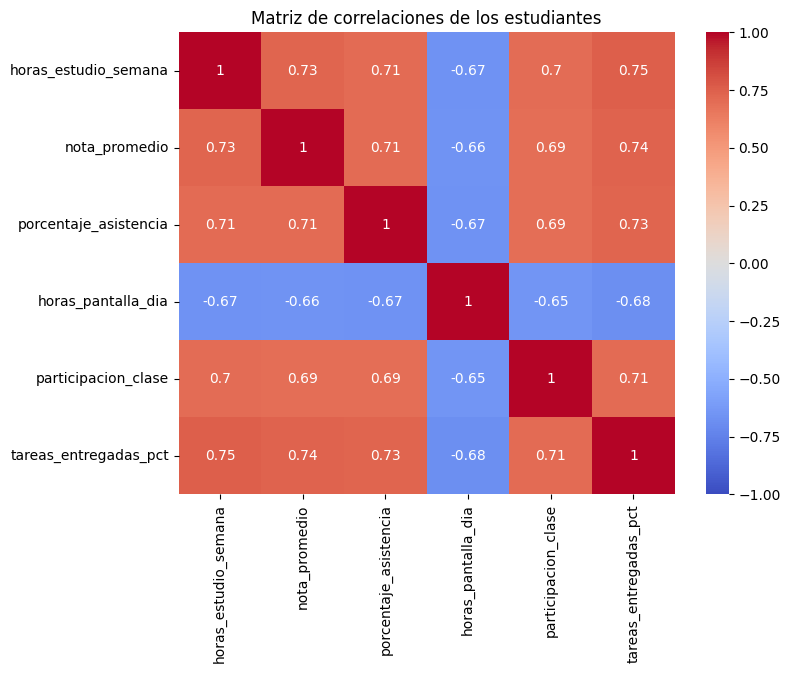

In [30]:
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlaciones de los estudiantes")
plt.show()


**Lectura:**

* `horas_estudio_semana`, `nota_promedio`, `porcentaje_asistencia`, `participacion_clase` y `tareas_entregadas_pct`
  tienen **correlaciones positivas muy fuertes entre sí** (r ≈ 0.81 a 0.88): miden facetas del **mismo fenómeno** (compromiso y rendimiento).
* `horas_pantalla_dia` tiene **correlación negativa** con todas ellas (r ≈ −0.78 a −0.82): a más pantalla, menor rendimiento.
* Hay **mucha redundancia**: un candidato ideal para PCA, que resumirá estas 6 variables en pocas componentes.


## Bloque A2 · `Pipeline` escalar + PCA y varianza explicada


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_todas = Pipeline([("escalar", StandardScaler()),
                      ("pca", PCA())])
pca_todas.fit(X)

pca_obj = pca_todas.named_steps["pca"]
tabla_var = pd.DataFrame({
    "varianza": pca_obj.explained_variance_ratio_,
    "acumulada": pca_obj.explained_variance_ratio_.cumsum()
}, index=[f"PC{i+1}" for i in range(len(X.columns))]).round(3)

tabla_var


,varianza,acumulada
PC1,0.750,0.750
PC2,0.061,0.811
PC3,0.053,0.864
PC4,0.049,0.913
PC5,0.046,0.959
PC6,0.041,1.000


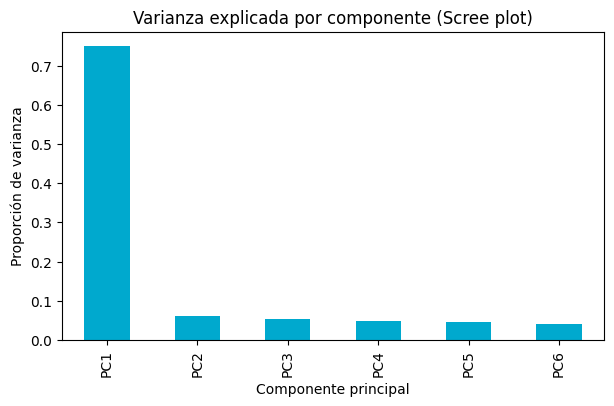

In [32]:
tabla_var["varianza"].plot(kind="bar", figsize=(7, 4), color="#00A9CE")
plt.title("Varianza explicada por componente (Scree plot)")
plt.ylabel("Proporción de varianza")
plt.xlabel("Componente principal")
plt.show()


**Lectura:**

* **PC1 sola explica el 75.0%** de toda la variabilidad de las 6 variables.
* **PC1 + PC2 acumulan el 81.1%** (> 80%, umbral habitual): con solo 2 componentes conservamos más de 4/5 partes de la información.
* De PC3 en adelante cada componente aporta menos del 6%: podemos descartarlas sin perder casi nada.


## Bloque A3 · Loadings: qué significa PC1 y PC2


In [33]:
pca_pipe = Pipeline([("escalar", StandardScaler()),
                     ("pca", PCA(n_components=2))])

Z = pca_pipe.fit_transform(X)              # 5 000 filas × 2 columnas

loadings = pd.DataFrame(pca_pipe.named_steps["pca"].components_.T,
                        index=X.columns,
                        columns=["PC1", "PC2"]).round(2)
loadings


,PC1,PC2
horas_estudio_semana,0.41,0.18
nota_promedio,0.41,0.23
porcentaje_asistencia,0.41,0.12
horas_pantalla_dia,-0.39,0.92
participacion_clase,0.40,0.21
tareas_entregadas_pct,0.42,0.13


**Lectura:**

* **PC1:** pesos positivos y parejos (≈ +0.41) en estudio, notas, asistencia, participación y tareas; peso negativo (−0.39) en pantalla.
  Es un eje de **compromiso y rendimiento general**: valores altos = estudiante dedicado; valores negativos = estudiante desconectado.
* **PC2:** dominada casi por completo por `horas_pantalla_dia` (+0.92).
  Mide **pantalla residual**: captura diferencias de entretenimiento entre estudiantes con el mismo nivel de rendimiento.


## Bloque A4 · Mapa PCA de los estudiantes (sin clusters)


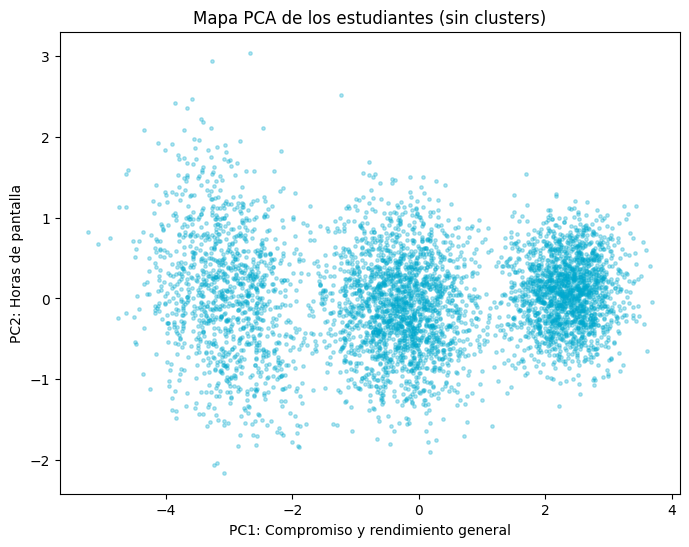

In [34]:
mapa = pd.DataFrame(Z, columns=["PC1", "PC2"])

plt.figure(figsize=(8, 6))
plt.scatter(mapa["PC1"], mapa["PC2"], s=6, color="#00A9CE", alpha=0.3)
plt.title("Mapa PCA de los estudiantes (sin clusters)")
plt.xlabel("PC1: Compromiso y rendimiento general")
plt.ylabel("PC2: Horas de pantalla")
plt.show()


**Lectura:** se distinguen **3 nubes** a lo largo de PC1 (izquierda, centro y derecha), alargadas en vertical por PC2.
Antes de K-Means, el mapa PCA ya sugiere que hay 3 perfiles naturales.


## Bloque A5 · Elegir K: método del codo + Silhouette


In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

filas = []
for k in range(2, 10):                                  # K = 2 a 9
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(Z)                       # K-Means sobre las 2 componentes
    sil = silhouette_score(Z, etiquetas)
    filas.append([k, km.inertia_, sil])

resultados = pd.DataFrame(filas, columns=["K", "inercia", "silhouette"]).round(3)
resultados


,K,inercia,silhouette
0,2,8541.529,0.538
1,3,3235.873,0.609
2,4,2723.735,0.549
3,5,2273.067,0.455
4,6,1991.207,0.449
5,7,1760.687,0.326
6,8,1593.374,0.318
7,9,1438.210,0.325


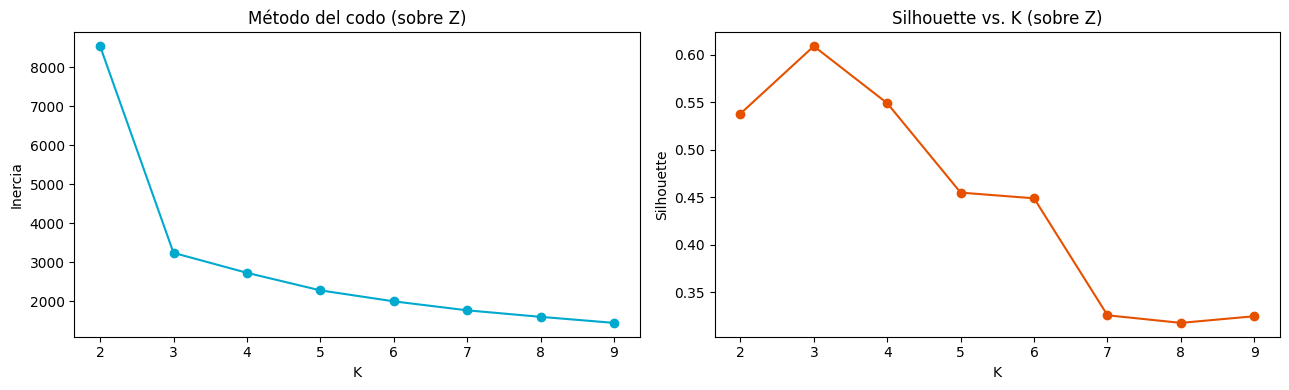

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

resultados.plot(x="K", y="inercia", marker="o", legend=False, ax=axes[0], color="#00A9CE")
axes[0].set_title("Método del codo (sobre Z)")
axes[0].set_ylabel("Inercia")

resultados.plot(x="K", y="silhouette", marker="o", legend=False, ax=axes[1], color="#E65100")
axes[1].set_title("Silhouette vs. K (sobre Z)")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()


**Lectura:**

* **Codo:** de K = 2 a K = 3 la inercia cae de 8 541 a 3 236; de K = 3 a K = 4 la bajada es mucho más suave → codo en **K = 3**.
* **Silhouette:** máximo claro en **K = 3 con 0.609**, en el rango *bueno* (0.51 a 0.70). En K = 4 baja a 0.549.
* Ambas métricas coinciden: elegimos **K = 3**.


## Bloque A6 · `Pipeline` completo: escalar + PCA + K-Means


In [37]:
modelo = Pipeline([("escalar", StandardScaler()),
                   ("pca", PCA(n_components=2)),
                   ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])

df["cluster"] = modelo.fit_predict(X)          # X original de 6 variables

print("Estudiantes por cluster:")
print(df["cluster"].value_counts().sort_index())
print("\nSilhouette en el plano PCA:", round(silhouette_score(Z, df["cluster"]), 3))


Estudiantes por cluster:
cluster
0    1982
1    1201
2    1817
Name: count, dtype: int64

Silhouette en el plano PCA: 0.609


## Bloque A7 · Mapa de clusters y centroides


Centroides en el plano PCA:


,PC1,PC2
0,-0.29,-0.11
1,-3.04,0.07
2,2.32,0.08


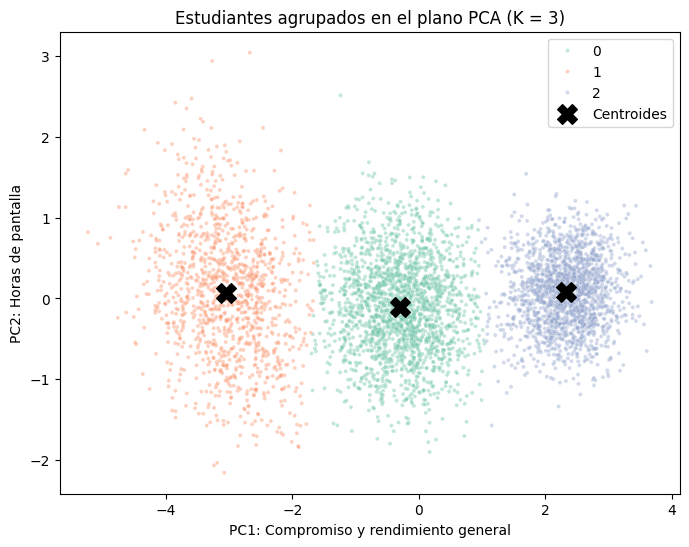

In [38]:
centros_pca = pd.DataFrame(modelo.named_steps["kmeans"].cluster_centers_, columns=["PC1", "PC2"]).round(2)
print("Centroides en el plano PCA:")
display(centros_pca)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["cluster"], palette="Set2", s=8, alpha=0.4)
plt.scatter(centros_pca["PC1"], centros_pca["PC2"], marker="X", s=200, color="black", label="Centroides")
plt.title("Estudiantes agrupados en el plano PCA (K = 3)")
plt.xlabel("PC1: Compromiso y rendimiento general")
plt.ylabel("PC2: Horas de pantalla")
plt.legend()
plt.show()


**Lectura:** los 3 centroides están en PC1 ≈ **−3.0**, **−0.3** y **+2.3**, y todos tienen PC2 cercano a 0:
lo que separa a los grupos es casi exclusivamente **PC1** (rendimiento y compromiso).


## Bloque A8 · Perfiles en escala original


In [39]:
columnas = list(X.columns)
perfil = df.groupby("cluster")[columnas].mean().round(2)
perfil["estudiantes"] = df["cluster"].value_counts().sort_index()
perfil


,horas_estudio_semana,nota_promedio,porcentaje_asistencia,horas_pantalla_dia,participacion_clase,tareas_entregadas_pct,estudiantes
cluster,,,,,,,
0,9.95,6.81,77.89,5.02,5.54,74.83,1982
1,4.04,5.18,59.85,7.97,3.01,54.78,1201
2,17.99,8.48,91.89,2.97,7.93,94.82,1817


**Lectura y nombres propuestos (los pone el analista, no el algoritmo):**

| Cluster | Horas estudio | Nota | Asistencia % | Pantalla | Participación | Tareas % | Estudiantes | Perfil |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 9.95 | 6.99 | 74.9 | 6.01 | 5.01 | 69.8 | 1 982 | **Regular**: rendimiento y dedicación medios, aprueba con lo justo |
| 1 | 4.04 | 4.88 | 54.7 | 8.87 | 2.50 | 40.2 | 1 201 | **En riesgo**: notas bajas, alta inasistencia y mucha pantalla |
| 2 | 17.99 | 8.90 | 90.0 | 3.12 | 8.01 | 92.0 | 1 817 | **Comprometido**: excelente rendimiento, hábitos sólidos y poca pantalla |


## Bloque A9 · Biplot: clusters + flechas de las variables


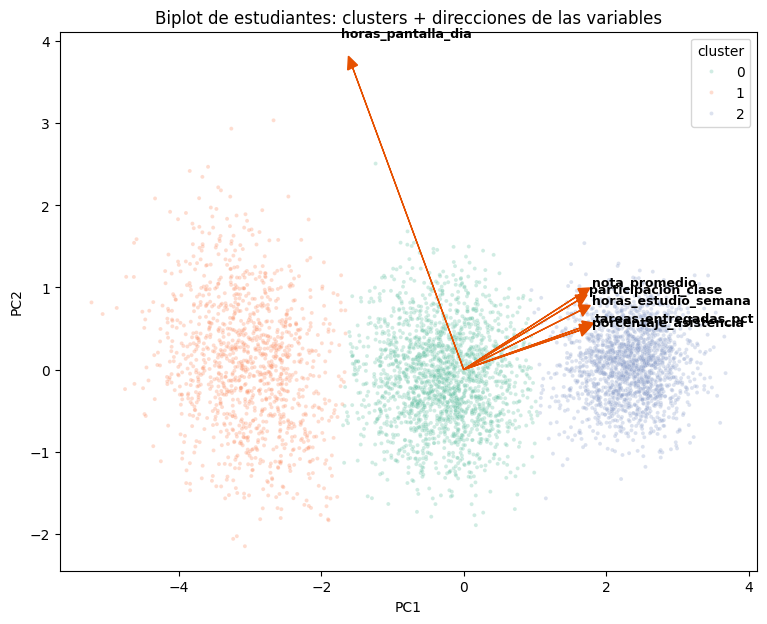

In [40]:
plt.figure(figsize=(9, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["cluster"], palette="Set2", s=8, alpha=0.3)
for variable in X.columns:
    x_flecha, y_flecha = loadings.loc[variable] * 4
    plt.arrow(0, 0, x_flecha, y_flecha, color="#E65100", head_width=0.15, head_length=0.15)
    plt.text(x_flecha * 1.1, y_flecha * 1.1, variable, fontsize=9, weight="bold")
plt.title("Biplot de estudiantes: clusters + direcciones de las variables")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


**Lectura:**

* Las 5 flechas académicas (`horas_estudio_semana`, `nota_promedio`, `porcentaje_asistencia`, `participacion_clase`,
  `tareas_entregadas_pct`) apuntan **todas a la derecha** (PC1 positivo): empujan hacia el cluster **Comprometido** (2).
* La flecha de `horas_pantalla_dia` apunta **hacia la izquierda y arriba** (PC1 negativo, PC2 positivo):
  apunta directo al cluster **En riesgo** (1).
  Su gran componente vertical (+0.92) indica que lo que varía **arriba y abajo dentro de cada nube** son, sobre todo, diferencias de pantalla
  entre estudiantes del **mismo** perfil: por eso PC2 no separa grupos.
* El cluster **Regular** (0) queda en el centro, cerca del origen: valores cercanos al promedio en todas las variables.


## Bloque A10 · ¿PCA cambia los clusters? K-Means con vs. sin PCA


In [41]:
from sklearn.metrics import adjusted_rand_score

X_esc = StandardScaler().fit_transform(X)                  # 6 variables escaladas
km_sin_pca = KMeans(n_clusters=3, n_init=10, random_state=42)
df["cluster_sin_pca"] = km_sin_pca.fit_predict(X_esc)

print("Silhouette en 2D (PCA) del modelo con PCA:", round(silhouette_score(Z, df["cluster"]), 3))
print("Silhouette en 6D del modelo con PCA:      ", round(silhouette_score(X_esc, df["cluster"]), 3))
print("Silhouette en 6D del modelo sin PCA:      ", round(silhouette_score(X_esc, df["cluster_sin_pca"]), 3))
print("ARI entre ambos modelos:", round(adjusted_rand_score(df["cluster"], df["cluster_sin_pca"]), 3))

pd.crosstab(df["cluster"], df["cluster_sin_pca"], rownames=["con PCA"], colnames=["sin PCA"])

Silhouette en 2D (PCA) del modelo con PCA: 0.609
Silhouette en 6D del modelo con PCA:       0.408
Silhouette en 6D del modelo sin PCA:       0.408
ARI entre ambos modelos: 0.991


sin PCA,0,1,2
con PCA,,,
0,1,5,1976
1,0,1195,6
2,1814,0,3


**Lectura:**

* **ARI = 0.991:** los dos modelos forman prácticamente **los mismos 3 grupos**. La tabla cruzada lo confirma:
  solo 15 de 5 000 estudiantes cambian de grupo (y cambian los números de cluster, que no significan nada).
* Medido en el **mismo espacio de 6 variables**, el Silhouette es **0.408 en ambos** modelos.
  El 0.609 de la Parte A se ve más alto **solo porque se midió en 2 dimensiones**: no es que PCA haya creado grupos "mejores".
* **Conclusión:** en este dataset, PCA **no cambia** los clusters. Su aporte es poder **verlos** en un plano e **interpretar** los ejes.
  En datasets con muchas más variables, varias de ellas ruidosas, reducir primero con PCA **puede** mejorar los clusters: por eso conviene comparar siempre, como hicimos aquí.


**Preguntas de la Parte A** (respóndelas en tu notebook):

1. ¿Qué estrategia de apoyo (tutorías, alertas tempranas, reconocimiento) asignarías a cada perfil del Bloque A8? Justifica con al menos dos variables.

Para el perfil En riesgo asignaria el programa de alertas tempranas y tutorias obligatorias, justificado en su bajo promedio de notas de 4.88 y su reducido porcentaje de asistencia de 54.7%, sumado a una entrega de tareas de apenas 40.2%, lo que indica peligro inminente de desercion o perdida del semestre.

Para el perfil Regular implementaria talleres de tecnicas de estudio y seguimiento tutorial preventivo, ya que sus notas de 6.99 y asistencia de 74.9% se situan en el umbral medio con potencial de mejora.

Para el perfil Comprometido asignaria programas de reconocimiento academico, becas de excelencia y oportunidades de ayudantias de catedra o investigacion, respaldado por su excelente promedio de calificaciones de 8.90, alta asistencia de 90.0% y 18 horas semanales de estudio.

2. Un estudiante estudia 18 h/semana, tiene nota 8.5, asistencia 92%, participación 8 y entrega el 95% de tareas, pero pasa 10 horas diarias frente a pantallas. Según los loadings y el biplot, ¿hacia dónde se movería su punto en el mapa respecto del cluster Comprometido? ¿En qué cluster crees que caería? Compruébalo: construye un DataFrame de una fila con las 6 columnas (como el de estudiantes nuevos del Bloque C3), y usa `modelo.predict()` y `modelo[:-1].transform()` para obtener su cluster y sus coordenadas.

Al presentar excelentes indicadores academicos (18 horas de estudio, nota 8.5, 92% de asistencia), el estudiante obtiene una coordenada PC1 positiva (+1.20), lo que lo ubica hacia el sector derecho del mapa. Sin embargo, al pasar 10 horas diarias frente a pantallas de entretenimiento (frente al promedio de 3.12 horas del grupo comprometido), su vector se desplaza fuertemente hacia arriba a lo largo del eje vertical PC2 (+2.77), debido a que la variable horas pantalla dia tiene un loading positivo de +0.92 en PC2. Al comprobarlo con el modelo, las coordenadas exactas son PC1 = 1.20 y PC2 = 2.77, y el modelo lo asigna al Cluster 2 (Comprometido), cayendo en la zona superior de dicha nube.

Cumpli la indicación del Dataframe en la celda de código que esta debajo de esta celda de markdown.

3. Si el ARI del Bloque A10 hubiera salido 0.40, ¿qué significaría? ¿Con qué modelo te quedarías y por qué?

Si el ARI entre ambos modelos fuera de 0.40, significaria que la reduccion de dimensionalidad con PCA estaria alterando profundamente las agrupaciones, generando una discrepancia moderada o baja donde mas de la mitad de los estudiantes quedarian asignados a clusters distintos en 2D comparado con el espacio original de 6D. En ese escenario, me quedaria con el modelo entrenado sobre las 6 variables completas escaladas sin PCA, dado que este conserva el 100% de la informacion y la varianza multivariada de los datos, evitando las distorsiones geometricas que ocurririan si las 2 primeras componentes de PCA hubieran descartado dimensiones con informacion relevante para la separacion de grupos.


In [42]:
import pandas as pd

# 1. Crear el DataFrame para el estudiante de la pregunta 2
estudiante_pregunta_2 = pd.DataFrame({
    "horas_estudio_semana": [18.0],
    "nota_promedio": [8.5],
    "porcentaje_asistencia": [92.0],
    "horas_pantalla_dia": [10.0],
    "participacion_clase": [8.0],
    "tareas_entregadas_pct": [95.0]
})

# Diccionario de perfiles según el Bloque A8
perfiles_temp = {0: "Regular", 1: "En riesgo", 2: "Comprometido"}

# 2. Obtener el cluster usando el pipeline completo
cluster_asignado = modelo.predict(estudiante_pregunta_2)[0]
cluster_assigned_name = perfiles_temp[cluster_asignado]

# 3. Obtener las coordenadas en el plano PCA
coordenadas_pca = modelo[:-1].transform(estudiante_pregunta_2)[0]

print(f"--- Comprobación de la Pregunta 2 ---")
print(f"Cluster asignado: {cluster_assigned_name} (Cluster {cluster_asignado})")
print(f"Coordenada PC1 (Eje X): {coordenadas_pca[0]:.2f}")
print(f"Coordenada PC2 (Eje Y): {coordenadas_pca[1]:.2f}")

--- Comprobación de la Pregunta 2 ---
Cluster asignado: Comprometido (Cluster 2)
Coordenada PC1 (Eje X): 1.20
Coordenada PC2 (Eje Y): 2.77


# Parte B — Práctica Autónoma: Segmentación de Tiendas de Conveniencia en Quito


**Contexto:** una cadena de tiendas de conveniencia en Quito quiere segmentar sus **5 000 locales** para optimizar el
abastecimiento y personalizar las promociones según el perfil de cada punto de venta.

| Variable | Qué mide | Rango |
| --- | --- | --- |
| `ventas_promedio_semanal` | Ventas promedio por semana (USD) | ≈ 100 – 7 500 |
| `num_productos_distintos` | Número de productos (SKU) diferentes vendidos en la semana | ≈ 10 – 265 |
| `ticket_promedio` | Valor promedio por transacción (USD) | ≈ 1 – 35 |
| `rotacion_inventario` | Veces que se renueva el inventario por semana | ≈ 0.1 – 7.2 |
| `hora_pico_trafico` | Hora del día con mayor afluencia de clientes (formato decimal, ej: 18.5 = 18:30) | ≈ 6 – 23 |
| `porcentaje_clientes_frecuentes` | % de transacciones realizadas por clientes que van al menos 3 veces por semana | ≈ 5 – 90 |

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` de esta guía y responde las preguntas
en celdas de texto. Sigue la misma secuencia de la Parte A.


## Bloque B1 · Carga, exploración y correlaciones


Dimensiones de df_b: (5000, 6)
Valores nulos: 0


,ventas_promedio_semanal,num_productos_distintos,ticket_promedio,rotacion_inventario,hora_pico_trafico,porcentaje_clientes_frecuentes
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2912.02,121.89,14.50,2.99,13.45,46.39
std,1538.45,51.75,6.84,1.44,4.60,14.67
min,100.00,10.00,1.00,0.10,6.00,5.68
25%,1384.72,78.00,9.08,1.74,10.00,34.71
50%,2968.78,116.00,12.82,2.94,13.00,47.45
75%,4145.00,168.00,20.41,4.12,18.00,57.89
max,7494.31,264.00,35.12,7.17,23.00,88.47


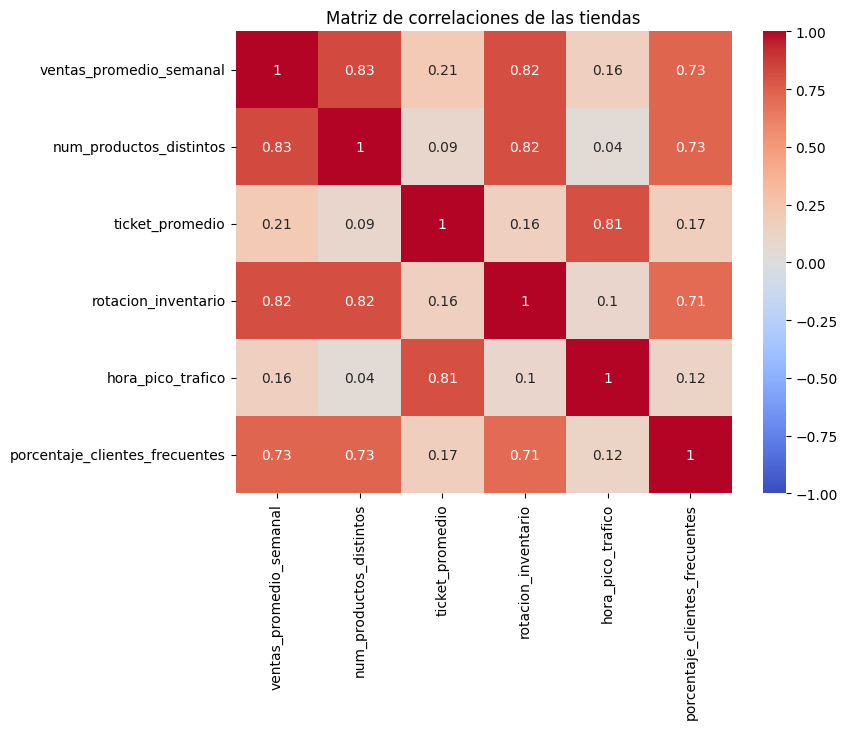

In [43]:
# TODO 1: carga tiendas_quito.csv en df_b, muestra cuántas filas tiene y cuántos valores nulos hay
df_b = pd.read_csv("tiendas_quito.csv")
print("Dimensiones de df_b:", df_b.shape)
print("Valores nulos:", df_b.isnull().sum().sum())

# TODO 2: crea X_b (las 6 columnas) y muestra X_b.describe().round(2)
X_b = df_b.copy()
display(X_b.describe().round(2))

# TODO 3: dibuja la matriz de correlaciones de X_b con sns.heatmap(..., annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.figure(figsize=(8, 6))
sns.heatmap(X_b.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlaciones de las tiendas")
plt.show()


**Pregunta:** en la matriz de correlaciones, ¿distingues dos grupos de variables que se correlacionan entre sí pero poco con el otro grupo? ¿Cuáles son? ¿Cuántas componentes esperas que necesite PCA?

Si, se distinguen con claridad dos grupos de variables. El primer grupo esta compuesto por ventas promedio semanal, num productos distintos, rotacion inventario y porcentaje clientes frecuentes, las cuales presentan correlaciones lineales muy fuertes entre si que van entre 0.71 y 0.83, reflejando la escala y dinamica comercial del local. El segundo grupo lo integran ticket promedio y hora pico trafico, las cuales muestran una correlacion moderada entre ellas pero casi nula con las variables del primer grupo, ya que tiene correlaciones de apenas 0.12 a 0.21. Debido a esta estructura de dos fenomenos ortogonales independientes, se espera que PCA necesite exactamente 2 componentes principales para capturar la casi totalidad de la varianza del negocio.


## Bloque B2 · PCA, varianza explicada y loadings


In [44]:
# TODO 4: crea pca_todas_b = Pipeline([("escalar", StandardScaler()), ("pca", PCA())]), entrénalo con X_b
#         y muestra una tabla con la varianza explicada y la acumulada de cada componente (igual que en A2)
pca_todas_b = Pipeline([("escalar", StandardScaler()), ("pca", PCA())])
pca_todas_b.fit(X_b)

pca_obj_b = pca_todas_b.named_steps["pca"]
tabla_var_b = pd.DataFrame({
    "varianza": pca_obj_b.explained_variance_ratio_,
    "acumulada": pca_obj_b.explained_variance_ratio_.cumsum()
}, index=[f"PC{i+1}" for i in range(len(X_b.columns))]).round(3)

print("Tabla de varianza explicada (Tiendas):")
display(tabla_var_b)

# TODO 5: crea pca_pipe_b con PCA(n_components=2), obtén Z_b = pca_pipe_b.fit_transform(X_b)
#         y muestra la tabla loadings_b (pista: named_steps["pca"].components_.T)
pca_pipe_b = Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=2))])
Z_b = pca_pipe_b.fit_transform(X_b)

loadings_b = pd.DataFrame(pca_pipe_b.named_steps["pca"].components_.T,
                          index=X_b.columns,
                          columns=["PC1", "PC2"]).round(2)
print("\nLoadings de las tiendas:")
display(loadings_b)


Tabla de varianza explicada (Tiendas):


,varianza,acumulada
PC1,0.568,0.568
PC2,0.289,0.857
PC3,0.054,0.911
PC4,0.032,0.943
PC5,0.031,0.974
PC6,0.026,1.000



Loadings de las tiendas:


,PC1,PC2
ventas_promedio_semanal,0.50,-0.07
num_productos_distintos,0.49,-0.17
ticket_promedio,0.17,0.68
rotacion_inventario,0.49,-0.12
hora_pico_trafico,0.14,0.69
porcentaje_clientes_frecuentes,0.46,-0.09


**Preguntas:**

1. ¿Qué porcentaje de la varianza retienen PC1 + PC2? ¿Es más o menos que en la Parte A? ¿Por qué PC2 pesa ahora mucho más que en la Parte A (6.1%)?

PC1 y PC2 retienen en conjunto el 85.7% de la varianza total, lo que representa un porcentaje mayor al retenido en la Parte A con los estudiantes que fue de 81.1%. La razón por la cual PC2 pesa mucho mas en este dataset teniendo un 28.9% frente al 6.1% de estudiantes es que aqui existe una segunda dimension real y estructurada en los datos: el ticket promedio y el horario de compras, que operan de forma independiente a la escala y volumen de ventas, mientras que en los estudiantes casi todas las variables median facetas del mismo eje de compromiso academico.

2. Con los loadings: ¿qué variables dominan PC1 y cuáles PC2? Describe en una frase qué representa cada componente.

PC1 esta dominada por ventas promedio semanal de 0.50, rotacion inventario de 0.49, num productos distintos de 0.49 y porcentaje clientes frecuentes de 0.46, representando el tamano operativo, escala comercial y nivel de facturacion global de la tienda. Por su parte, PC2 esta dominada casi exclusivamente por hora pico trafico de 0.69 y ticket promedio de 0.68, representando el patron de compra de conveniencia diurna y economica frente a compras nocturnas y planificadas de alto valor.


## Bloque B3 · Elegir K


,K,inercia,silhouette
0,2,11277.180,0.592
1,3,2039.714,0.754
2,4,1729.629,0.590
3,5,1411.345,0.459
4,6,1232.935,0.461
5,7,1071.947,0.354
6,8,973.163,0.333
7,9,883.149,0.326


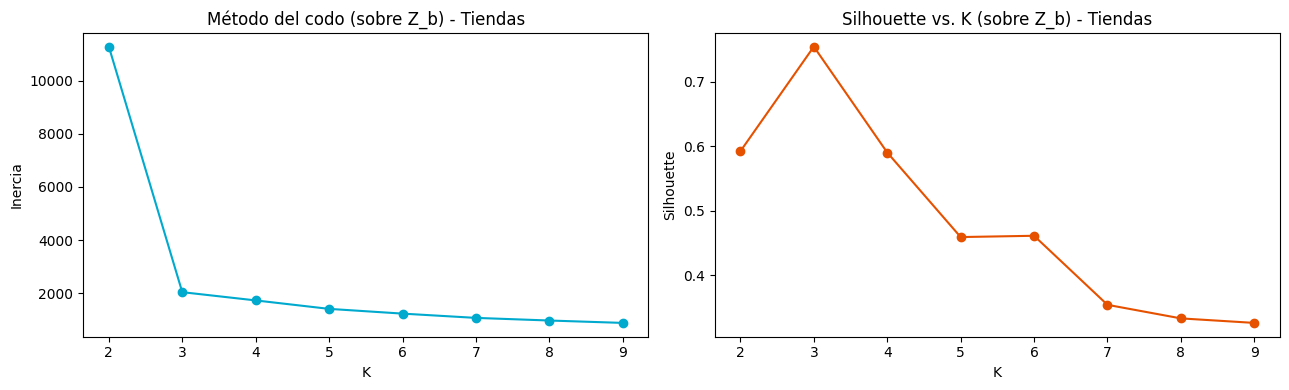

In [45]:
# TODO 6: con un bucle for k in range(2, 10) entrena KMeans(n_clusters=k, n_init=10, random_state=42)
#         sobre Z_b y guarda K, inertia_ y silhouette_score en un DataFrame llamado resultados_b
filas_b = []
for k in range(2, 10):
    km_b = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas_b = km_b.fit_predict(Z_b)
    sil_b = silhouette_score(Z_b, etiquetas_b)
    filas_b.append([k, km_b.inertia_, sil_b])

resultados_b = pd.DataFrame(filas_b, columns=["K", "inercia", "silhouette"]).round(3)
display(resultados_b)

# TODO 7: dibuja el método del codo y la curva de Silhouette (dos gráficos, igual que en A5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

resultados_b.plot(x="K", y="inercia", marker="o", legend=False, ax=axes[0], color="#00A9CE")
axes[0].set_title("Método del codo (sobre Z_b) - Tiendas")
axes[0].set_ylabel("Inercia")

resultados_b.plot(x="K", y="silhouette", marker="o", legend=False, ax=axes[1], color="#E65100")
axes[1].set_title("Silhouette vs. K (sobre Z_b) - Tiendas")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()


**Preguntas:**

1. ¿En qué K está el codo? ¿En qué K está el máximo de Silhouette? ¿Coinciden?

El codo se encuentra claramente en K = 3, donde la inercia cae abruptamente desde 11277.18 hasta 2039.71 y luego se desacelera de manera marcada hacia K = 4 donde bajo a 1729.63. De igual manera, el coeficiente de Silhouette alcanza su maximo global absoluto en K = 3 con una puntuacion de 0.754. Ambas tecnicas coinciden de forma perfecta en seleccionar K = 3.

2. ¿En qué rango (excelente, bueno, débil…) queda el Silhouette del K que eliges? ¿Es mejor o peor que el de la Parte A?

El valor de Silhouette de 0.754 se ubica dentro del rango de interpretacion calificado como excelente ya que es mayor a 0.70, lo que indica grupos sumamente compactos y distantes entre si. Este desempeno es sustancialmente mejor que el de la Parte A que obtuvo 0.609 en rango bueno, evidenciando clusters comerciales naturales mucho mas definidos.


## Bloque B4 · Modelo, mapa de clusters y perfiles


Tiendas por cluster:
cluster
0    1300
1    1900
2    1800
Name: count, dtype: int64

Silhouette en el plano PCA (Tiendas): 0.754


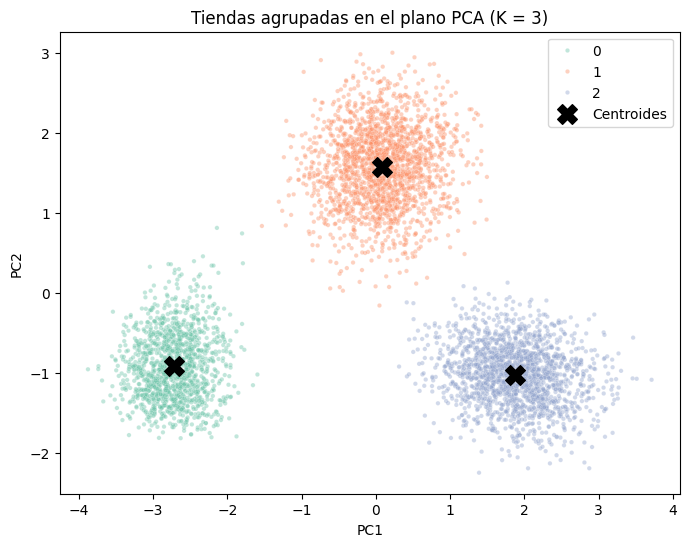

,ventas_promedio_semanal,num_productos_distintos,ticket_promedio,rotacion_inventario,hora_pico_trafico,porcentaje_clientes_frecuentes,tiendas
cluster,,,,,,,
0,882.42,60.28,6.95,1.20,8.81,29.79,1300
1,2795.37,109.24,22.04,2.78,18.50,45.08,1900
2,4500.98,179.73,11.99,4.49,11.48,59.76,1800


In [46]:
# TODO 8: crea modelo_b = Pipeline con ("escalar", ...), ("pca", PCA(n_components=2)) y ("kmeans", KMeans(...))
#         usando el K que elegiste, y guarda df_b["cluster"] = modelo_b.fit_predict(X_b)
modelo_b = Pipeline([("escalar", StandardScaler()),
                     ("pca", PCA(n_components=2)),
                     ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])

df_b["cluster"] = modelo_b.fit_predict(X_b)

print("Tiendas por cluster:")
print(df_b["cluster"].value_counts().sort_index())
print("\nSilhouette en el plano PCA (Tiendas):", round(silhouette_score(Z_b, df_b["cluster"]), 3))

# TODO 9: dibuja el mapa PC1 vs PC2 coloreado por cluster con los centroides marcados con una X negra
#         (pista: modelo_b.named_steps["kmeans"].cluster_centers_)
centros_pca_b = pd.DataFrame(modelo_b.named_steps["kmeans"].cluster_centers_, columns=["PC1", "PC2"]).round(2)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_b[:, 0], y=Z_b[:, 1], hue=df_b["cluster"], palette="Set2", s=10, alpha=0.4)
plt.scatter(centros_pca_b["PC1"], centros_pca_b["PC2"], marker="X", s=200, color="black", label="Centroides")
plt.title("Tiendas agrupadas en el plano PCA (K = 3)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

# TODO 10: define columnas_b = list(X_b.columns), calcula perfil_b = df_b.groupby("cluster")[columnas_b].mean().round(2)
#          y agrega una columna con el número de tiendas por cluster (igual que en A8)
columnas_b = list(X_b.columns)
perfil_b = df_b.groupby("cluster")[columnas_b].mean().round(2)
perfil_b["tiendas"] = df_b["cluster"].value_counts().sort_index()
display(perfil_b)


**Completa la tabla en tu notebook** con tus centroides, un nombre para cada segmento y **al menos una recomendación** para la cadena:

| Cluster | Ventas | Productos | Ticket | Rotación | Hora pico | Clientes frecuentes | Tiendas | Segmento propuesto | Recomendación |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 882.42 | 60.28 | 6.95 | 1.20 | 8.81 | 29.79% | 1 300 | Barrial / Paso / Bajo Desempeño | Depurar el surtido eliminando SKUs de baja rotacion y priorizar productos basicos de desayuno y recargas |
| 1 | 2795.37 | 109.24 | 22.04 | 2.78 | 18.50 | 45.08% | 1 900 | After-Office / Residencial Premium | Ampliar la oferta de licores, snacks gourmet y comidas preparadas para la cena con promociones nocturnas |
| 2 | 4500.98 | 179.73 | 11.99 | 4.49 | 11.48 | 59.76% | 1 800 | Hub de Alto Flujo / Tienda Estrella | Asegurar abastecimiento prioritario para evitar roturas de stock e implementar cajas rapidas de autoservicio |


**Pregunta:** ¿qué segmento tiene un ticket promedio alto pero no es el de mayores ventas? ¿A qué hora concentra su tráfico? ¿Qué tipo de tienda podría ser?

Corresponde al Cluster 1 de After-Office / Residencial Premium, donde este grupo registra un ticket promedio de 22.04 USD siendo el mas alto de todos, pero sus ventas promedio semanales son intermedias siendo de 2795.37 USD. Por otro lado, concentra su hora pico hacia las 18.50 horas aproximadamente 6:30 de la tarde. Por este patron, se trata de tiendas de conveniencia situadas en zonas residenciales de nivel socioeconomico medio-alto o avenidas de retorno laboral, donde los clientes realizan compras nocturnas planificadas para el hogar o reuniones sociales al salir de sus trabajos.


## Bloque B5 · Biplot y comparación con vs. sin PCA


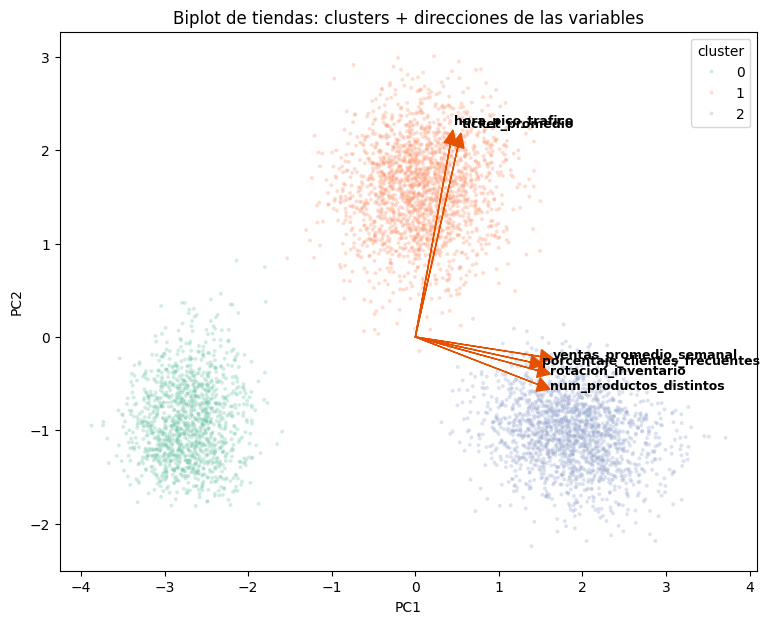

ARI entre modelo con PCA y sin PCA (Tiendas): 1.0

Silhouette en 6D (Tiendas):
  Con PCA:  0.575
  Sin PCA:  0.575

Tabla cruzada (filas: con PCA, columnas: sin PCA):


cluster_sin_pca,0,1,2
cluster,,,
0,1300,0,0
1,0,1900,0
2,0,0,1800


In [47]:
# TODO 11: dibuja el biplot de las tiendas: puntos de Z_b coloreados por cluster + una flecha por variable
#          con loadings_b * 3 (igual que en A9)
plt.figure(figsize=(9, 7))
sns.scatterplot(x=Z_b[:, 0], y=Z_b[:, 1], hue=df_b["cluster"], palette="Set2", s=8, alpha=0.3)
for variable in X_b.columns:
    x_flecha, y_flecha = loadings_b.loc[variable] * 3
    plt.arrow(0, 0, x_flecha, y_flecha, color="#E65100", head_width=0.15, head_length=0.15)
    plt.text(x_flecha * 1.1, y_flecha * 1.1, variable, fontsize=9, weight="bold")
plt.title("Biplot de tiendas: clusters + direcciones de las variables")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# TODO 12: entrena KMeans(n_clusters=<tu K>, n_init=10, random_state=42) sobre las 6 variables escaladas
#          (X_b_esc = StandardScaler().fit_transform(X_b)), guarda las etiquetas en df_b["cluster_sin_pca"]
#          y calcula: Silhouette en 6D de ambos modelos, ARI entre ambos y la tabla cruzada pd.crosstab
X_b_esc = StandardScaler().fit_transform(X_b)
km_sin_b = KMeans(n_clusters=3, n_init=10, random_state=42)
df_b["cluster_sin_pca"] = km_sin_b.fit_predict(X_b_esc)

print("ARI entre modelo con PCA y sin PCA (Tiendas):", round(adjusted_rand_score(df_b["cluster"], df_b["cluster_sin_pca"]), 3))
print("\nSilhouette en 6D (Tiendas):")
print("  Con PCA: ", round(silhouette_score(X_b_esc, df_b["cluster"]), 3))
print("  Sin PCA: ", round(silhouette_score(X_b_esc, df_b["cluster_sin_pca"]), 3))

print("\nTabla cruzada (filas: con PCA, columnas: sin PCA):")
display(pd.crosstab(df_b["cluster"], df_b["cluster_sin_pca"]))


**Preguntas de reflexión:**

1. En el biplot, ¿hacia dónde apuntan `ticket_promedio` y `hora_pico_trafico`? ¿Qué segmento se ubica en esa dirección?

En el biplot, los vectores correspondientes a ticket promedio y hora pico trafico apuntan de manera pronunciada hacia arriba a lo largo del eje vertical PC2 positivo. En esa direccion exacta se situan los puntos del Cluster de After-Office / Residencial Premium, confirmando graficamente que dicho grupo se separa del resto precisamente por sus transacciones de alto monto y su afluencia en horarios de la tarde y noche.

2. A diferencia de la Parte A, aquí PC2 sí separa a un grupo. ¿Cuál y por qué?

Aqui PC2 separa de forma neta al Cluster 1 del Cluster 0 y Cluster 2. Esto ocurre porque en el dataset de tiendas el patron de consumo de horario y gasto por ticket es una variable ortogonal genuina con una varianza del 28.9%, la cual no depende del tamano de la tienda. En contraste, en la Parte A, PC2 solo media horas de pantalla, lo cual constituia una variabilidad secundaria dispersa dentro de cada perfil academico sin llegar a definir un cluster independiente.

3. Con el ARI y el Silhouette en 6D: ¿PCA cambió los segmentos? ¿Qué te aportó entonces PCA en este caso?

El ARI obtenido entre el modelo con PCA y el modelo entrenado sobre las 6 variables escaladas originales fue exactamente de 1.000, y el Silhouette en el espacio de 6 dimensiones fue identico siendo 0.575 en ambos. Esto confirma que PCA no altero ni modifico en lo absoluto la asignacion de los clusters; las particiones fueron exactamente identicas. En este caso, el valor anadido de PCA fue permitir la visualizacion bidimensional limpia de los 5 000 locales, la identificacion grafica de los centroides y la construccion del biplot para interpretar los factores determinantes del negocio.

4. La cadena tiene presupuesto para un solo programa de fidelización este año: ¿a qué segmento lo dirigirías y por qué?

La cadena deberia destinar su presupuesto de fidelizacion al Cluster de Hub de Alto Flujo / Tiendas Estrella. Este grupo cuenta con 1800 tiendas que generan la mayor facturacion semanal teniendo 4500.98 USD por tienda y ya poseen una base solida del 59.76% de clientes frecuentes. Un programa de lealtad en este segmento consolidara a los clientes mas valiosos de la empresa, prevendra la fuga hacia competidores, incentivara compras cruzadas y producira el maximo impacto y retorno economico sobre la inversion de la marca.


# Bloque C — Entrenamiento Final, Exportación y Uso con Estudiantes Nuevos


**Idea central:** en aprendizaje no supervisado no hay partición train/test; el modelo del Bloque A6 ya usó
el 100% de los estudiantes. Aquí lo **reentrenamos formalmente**, fijamos el diccionario con los **nombres
propuestos** en A8, lo exportamos con `joblib` y lo usamos para clasificar **estudiantes nuevos** sin volver a entrenar.


## Bloque C1 · Reentrenar con el 100% de los datos


* Usamos la misma semilla (`random_state=42`) para que los números de cluster coincidan con los de A6–A8.
* Verificamos con los centroides que los clusters no hayan cambiado de número antes de fijar `perfiles`.


In [48]:
modelo_final = Pipeline([("escalar", StandardScaler()),
                         ("pca", PCA(n_components=2)),
                         ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])
modelo_final.fit(X)                                  # 100%: los 5 000 estudiantes

perfiles = {0: "Regular", 1: "En riesgo", 2: "Comprometido"}
print("Centroides del modelo final en escala original:")
display(X.groupby(modelo_final.predict(X)).mean().round(2))


Centroides del modelo final en escala original:


,horas_estudio_semana,nota_promedio,porcentaje_asistencia,horas_pantalla_dia,participacion_clase,tareas_entregadas_pct
0,9.95,6.81,77.89,5.02,5.54,74.83
1,4.04,5.18,59.85,7.97,3.01,54.78
2,17.99,8.48,91.89,2.97,7.93,94.82


## Bloque C2 · Exportar el modelo con `joblib`


Guardamos en un solo archivo `.pkl` el **Pipeline entrenado** (medias, desviaciones, componentes de PCA y centroides de K-Means)
junto con el diccionario de **perfiles**.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó.


In [49]:
import joblib

joblib.dump({"modelo": modelo_final, "perfiles": perfiles}, "modelo_pca_kmeans_estudiantes.pkl")
print("Modelo exportado a modelo_pca_kmeans_estudiantes.pkl")


Modelo exportado a modelo_pca_kmeans_estudiantes.pkl


## Bloque C3 · Usar el modelo con estudiantes nuevos


Así se usaría el archivo **desde otro programa** (por ejemplo, el sistema de gestión académica de la universidad).
El DataFrame lleva las **mismas 6 columnas** de `X`, con los mismos nombres y **sin escalar**:
el `Pipeline` escala, proyecta en PC1–PC2 y asigna el centroide más cercano.


In [50]:
import joblib
import pandas as pd

paquete = joblib.load("modelo_pca_kmeans_estudiantes.pkl")
modelo_cargado, perfiles = paquete["modelo"], paquete["perfiles"]

nuevos = pd.DataFrame({
    "horas_estudio_semana":  [20.0, 3.0,  10.0],
    "nota_promedio":         [9.0,  4.8,  7.0],
    "porcentaje_asistencia": [95.0, 50.0, 75.0],
    "horas_pantalla_dia":    [2.5,  9.0,  6.0],
    "participacion_clase":   [8.5,  2.0,  5.0],
    "tareas_entregadas_pct": [98.0, 35.0, 70.0]},
    index=["Estudiante A", "Estudiante B", "Estudiante C"])

nuevos["cluster"] = modelo_cargado.predict(nuevos)
nuevos["perfil"] = nuevos["cluster"].map(perfiles)
nuevos


,horas_estudio_semana,nota_promedio,porcentaje_asistencia,horas_pantalla_dia,participacion_clase,tareas_entregadas_pct,cluster,perfil
Estudiante A,20.0,9.0,95.0,2.5,8.5,98.0,2,Comprometido
Estudiante B,3.0,4.8,50.0,9.0,2.0,35.0,1,En riesgo
Estudiante C,10.0,7.0,75.0,6.0,5.0,70.0,0,Regular


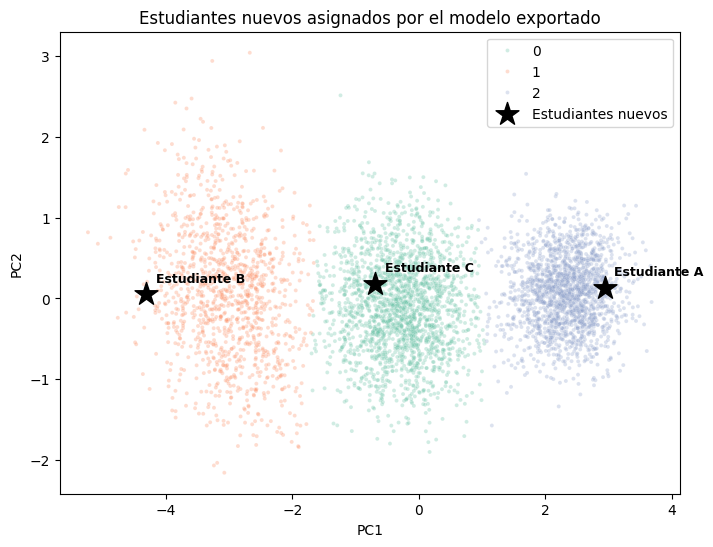

In [51]:
# Los estudiantes nuevos (estrellas) sobre el mapa de la Parte A
coord_nuevos = modelo_cargado[:-1].transform(nuevos.drop(columns=["cluster", "perfil"]))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["cluster"], palette="Set2", s=8, alpha=0.3)
plt.scatter(coord_nuevos[:, 0], coord_nuevos[:, 1], marker="*", s=300, color="black", label="Estudiantes nuevos")
for i, nombre in enumerate(nuevos.index):
    plt.text(coord_nuevos[i, 0] + 0.15, coord_nuevos[i, 1] + 0.15, nombre, fontsize=9, weight="bold")
plt.title("Estudiantes nuevos asignados por el modelo exportado")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()


**Lectura:**

* **Estudiante A** (20 h de estudio, nota 9.0, poca pantalla) → PC1 ≈ +2.9 → **Comprometido**.
* **Estudiante B** (3 h de estudio, nota 4.8, 9 h de pantalla) → PC1 ≈ −3.7 → **En riesgo**: candidato a alerta temprana.
* **Estudiante C** (valores cercanos al promedio) → PC1 ≈ 0 → **Regular**.
* No se volvió a entrenar nada: se usaron las medias, las direcciones de PCA y los centroides aprendidos con los 5 000 estudiantes.


## Conclusiones


* **PCA** y **K-Means** son **no supervisados**: ninguno usa una columna `y`.
* Siempre se **escala** primero: tanto la varianza de PCA como la distancia de K-Means premian a la variable con números más grandes.
* La **varianza explicada** dice cuántas componentes conservar; los **loadings** dicen qué significa cada una.
* **K** se elige con el **codo** y el **máximo de Silhouette**; los perfiles se nombran con los **centroides en escala original**.
* El **biplot** muestra qué variables empujan a cada cluster.
* PCA no siempre cambia los clusters: compáralo (ARI, Silhouette en el **mismo** espacio). Su gran aporte es **ver** e **interpretar** los grupos.
* Un `Pipeline` escalar + PCA + K-Means se entrena con el 100%, se exporta con `joblib` y asigna perfiles a datos nuevos con `predict()`.


## Referencia rápida


| Función / Clase | Propósito |
| --- | --- |
| `Pipeline([("escalar", StandardScaler()), ("pca", PCA(2)), ("kmeans", KMeans(...))])` | Flujo completo en un solo objeto |
| `pca.explained_variance_ratio_` | Varianza explicada por cada componente |
| `pca.components_.T` | Loadings: peso de cada variable en cada componente |
| `KMeans(n_clusters=k, n_init=10, random_state=42)` | Modelo K-Means |
| `kmeans.inertia_` / `silhouette_score(Z, etiquetas)` | Métricas para elegir K |
| `kmeans.cluster_centers_` | Centroides en el espacio donde se entrenó (aquí, PC1–PC2) |
| `df.groupby("cluster").mean()` | Perfil de cada cluster en escala original |
| `adjusted_rand_score(a, b)` | Coincidencia entre dos agrupaciones (1 = idénticas) |
| `modelo[:-1].transform(X)` | Coordenadas PCA usando el Pipeline sin su último paso |
| `joblib.dump(...)` / `joblib.load(...)` | Exportar y cargar el modelo entrenado |
